Running Statistical EDA on: /Users/kushrocks6306/Deep Learning Project/Proccessed Dataset/plantvillage_train_128x128

1. DATASET TAXONOMY & CLASS DISTRIBUTION SUMMARY
Total Images                 : 15,154
Total Classes                : 15 (3 unique crop species)
Healthy vs. Diseased Split   : 2,236 Healthy (14.8%) | 12,918 Diseased (85.2%)
Class Size Range             : Min = 128 | Median = 886 | Mean = 1010.3 ± 503.5 | Max = 2,334
Imbalance Ratio (Max / Min)  : 18.23x
Coefficient of Variation (CV): 0.498
Gini Inequality Coefficient  : 0.2597 (0 = balanced, 1 = imbalanced)
Shannon Equitability Index   : 0.9526 (3.72 / 3.91 bits)
Image Resolutions & Modes    : {'128x128 (RGB)': 2228}

2. EXACT RGB NORMALIZATION CONSTANTS (USE IN MODEL PREPROCESSING)
PlantVillage RGB Mean [0..1] : [0.4652, 0.4788, 0.4193]
PlantVillage RGB Std  [0..1] : [0.1878, 0.1648, 0.2032]
  (Compare to ImageNet Mean  : [0.4850, 0.4560, 0.4060] | Std: [0.2290, 0.2240, 0.2250])

3. PHOTOMETRIC DISTRIBUTION SHAPE (MEAN

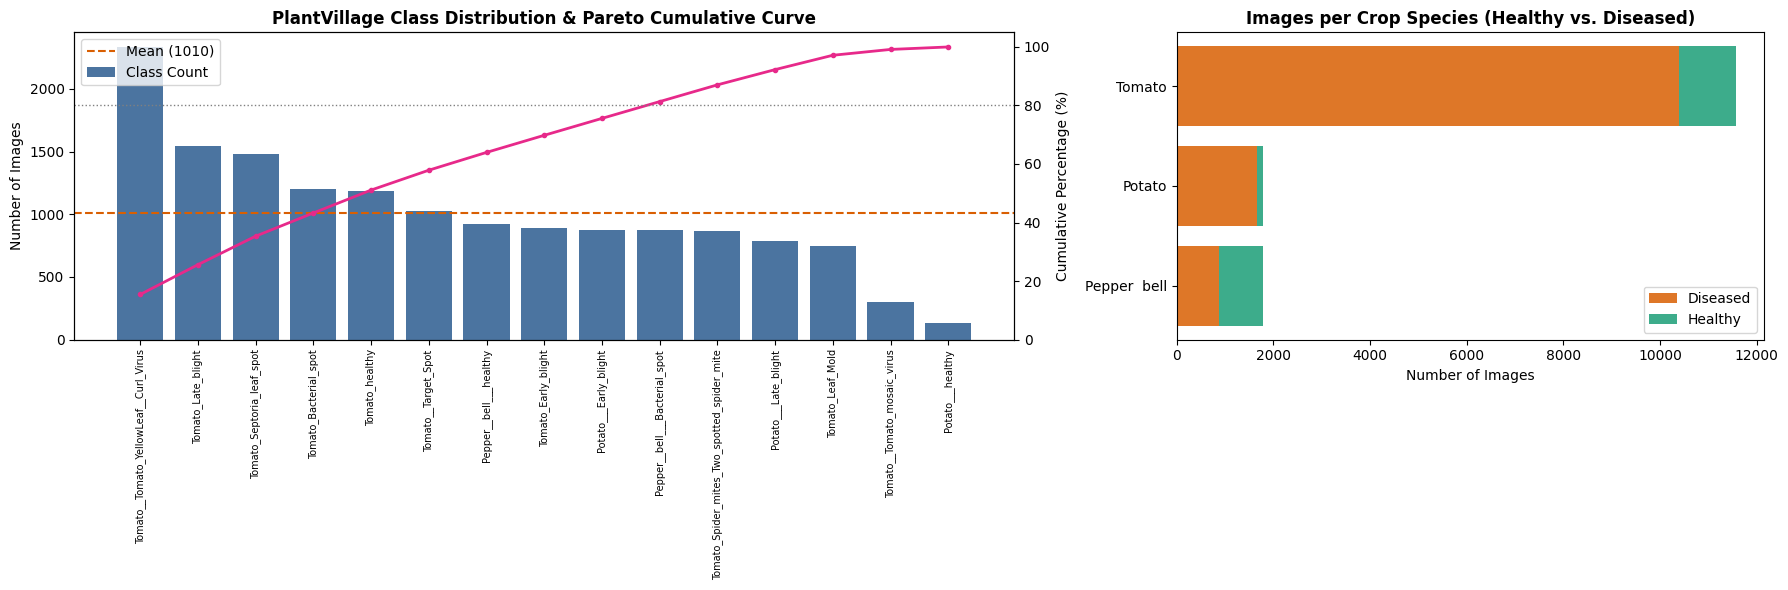

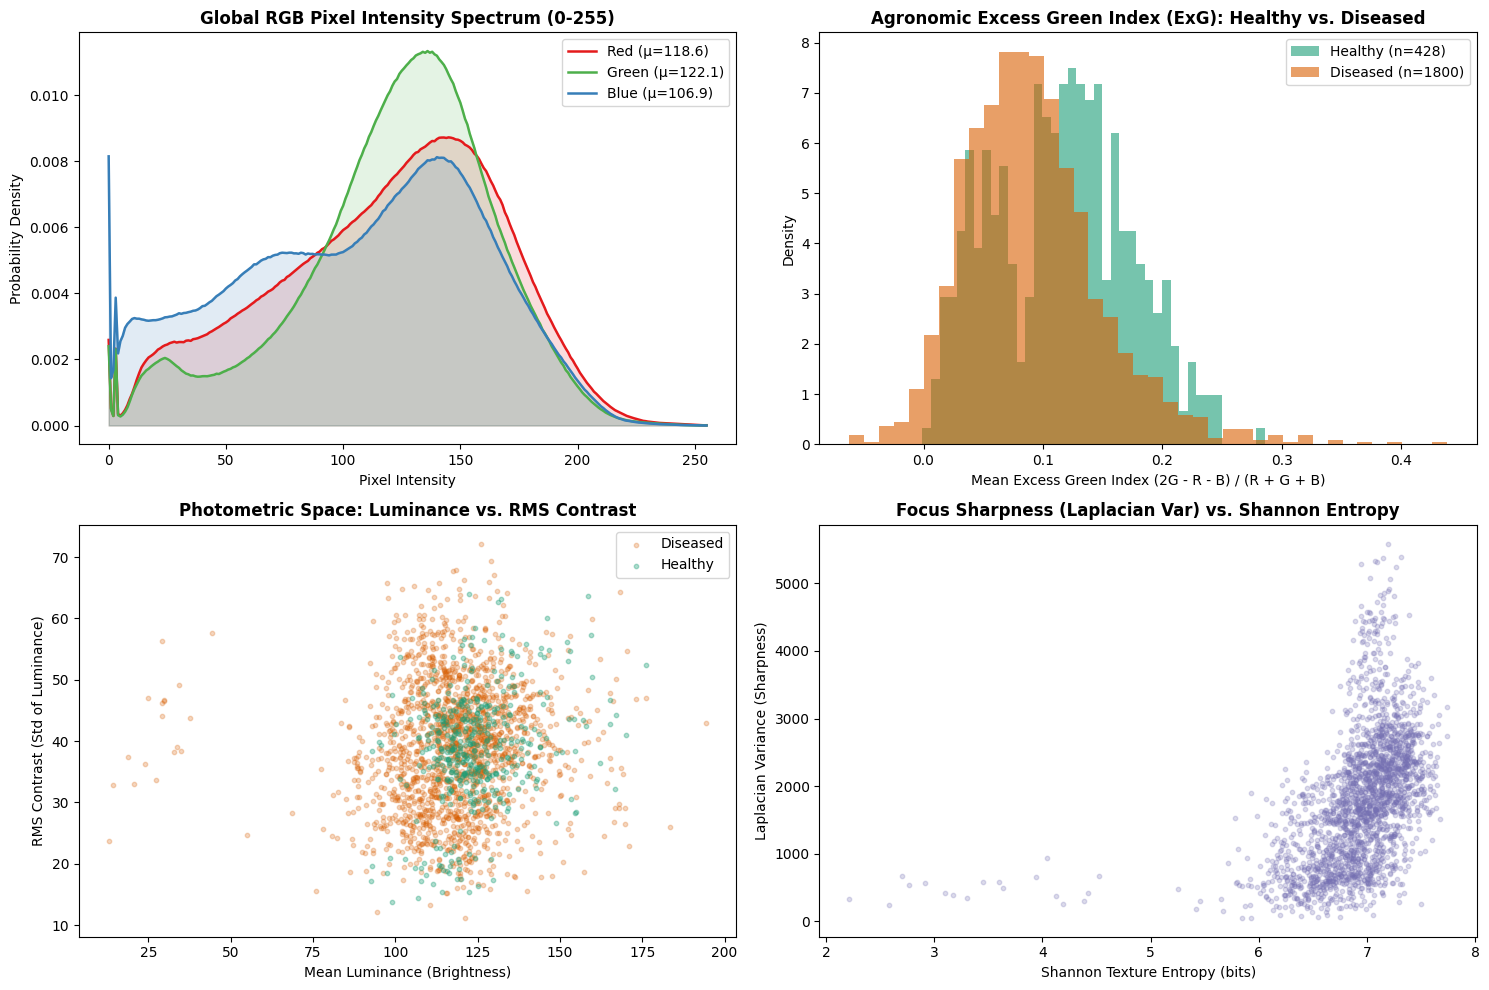

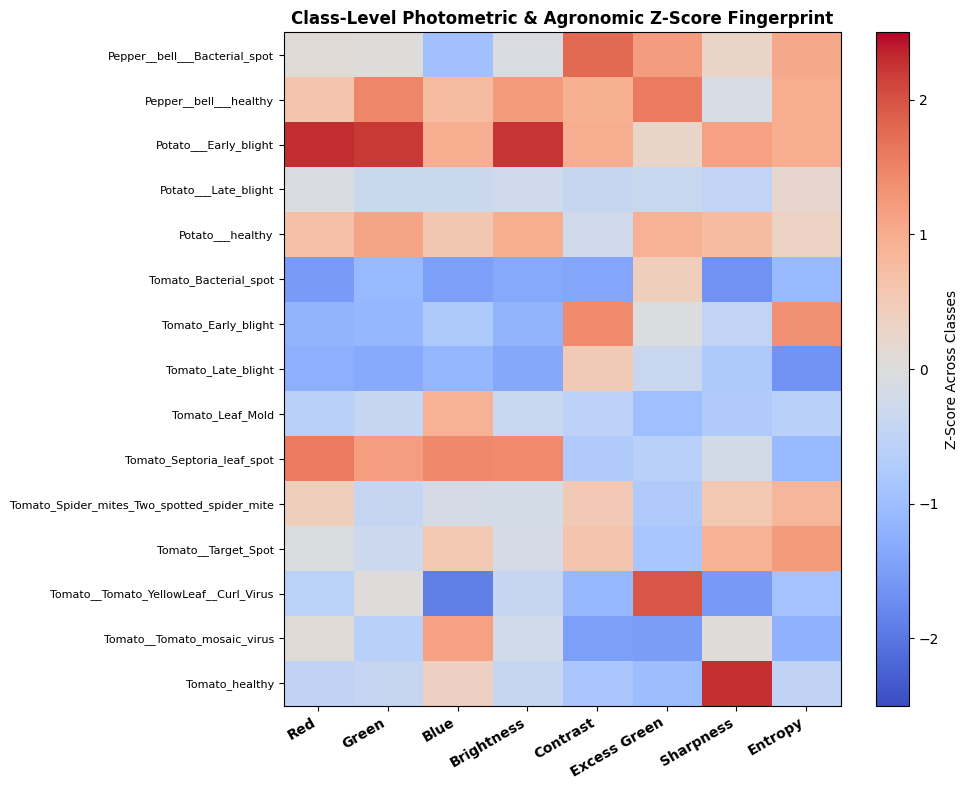

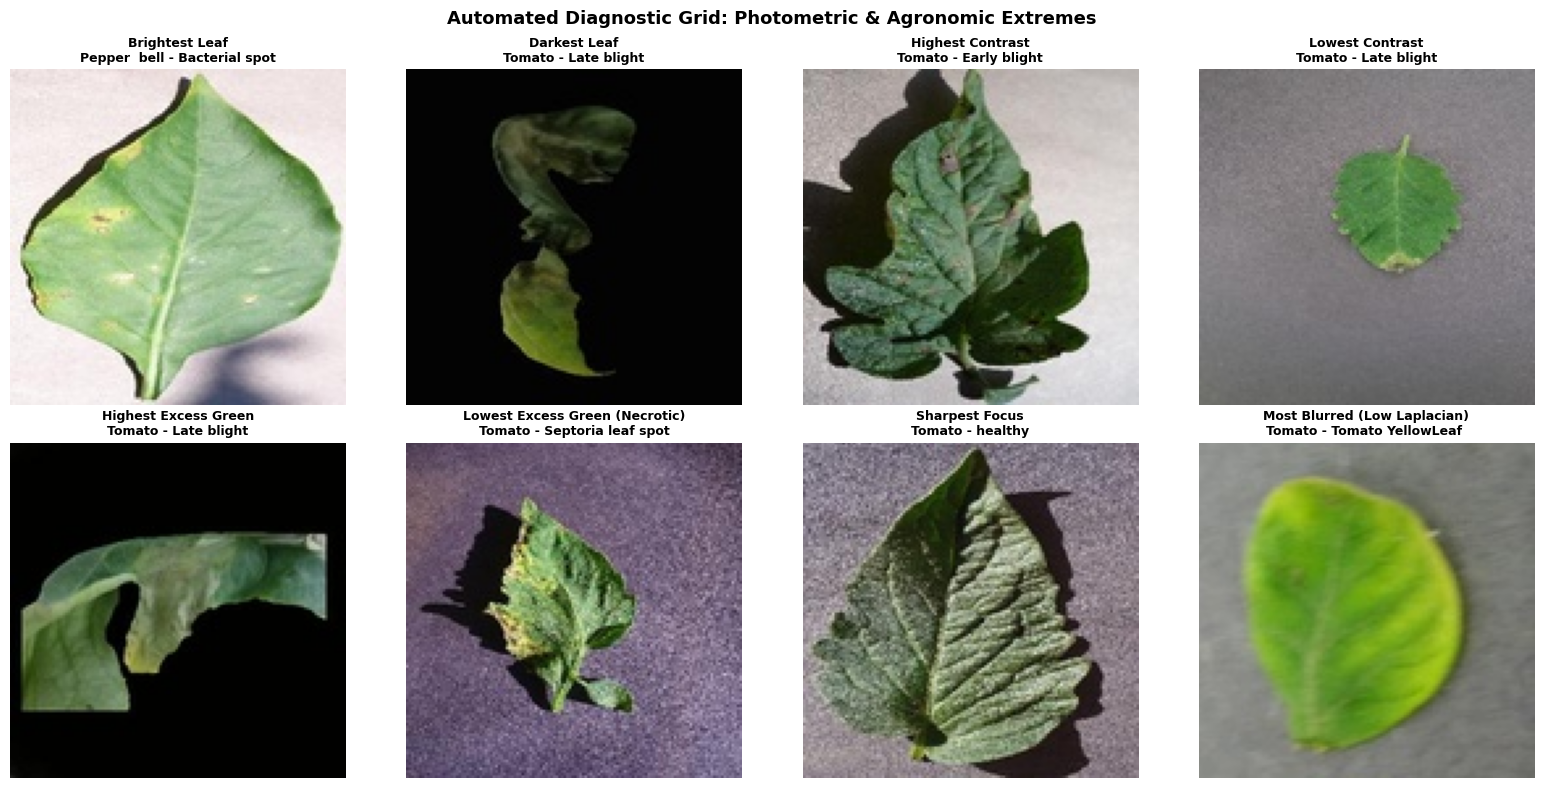

In [1]:
import csv
import math
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# ==============================================================================
# 1. CONFIGURATION & DATASET PATH
# ==============================================================================
# Point this to your processed 128x128 folder OR your raw PlantVillage folder
DATASET_DIR = Path('/Users/kushrocks6306/Deep Learning Project/Proccessed Dataset/plantvillage_train_128x128')

# Set to an integer (e.g., 150) for fast stratified pixel sampling (~5,700 images),
# or set to None to compute pixel statistics across 100% of images.
MAX_PIXEL_SAMPLES_PER_CLASS = 150
VALID_EXTS = {".jpg", ".jpeg", ".png"}

if (DATASET_DIR / "plantvillage dataset" / "color").exists():
    ROOT_DIR = DATASET_DIR / "plantvillage dataset" / "color"
elif (DATASET_DIR / "color").exists():
    ROOT_DIR = DATASET_DIR / "color"
elif DATASET_DIR.exists():
    ROOT_DIR = DATASET_DIR
else:
    raise FileNotFoundError(f"Dataset directory not found at: {DATASET_DIR.resolve()}")

print(f"Running Statistical EDA on: {ROOT_DIR.resolve()}\n")

# ==============================================================================
# 2. PURE-NUMPY STATISTICAL & AGRONOMIC HELPER FUNCTIONS
# ==============================================================================
def parse_class_name(folder_name):
    """Splits PlantVillage folder name into (Crop, Disease/Condition, Is_Healthy)."""
    if "___" in folder_name:
        crop, condition = folder_name.split("___", 1)
    elif "__" in folder_name:
        crop, condition = folder_name.split("__", 1)
    elif "_" in folder_name:
        parts = folder_name.split("_", 1)
        crop, condition = parts[0], parts[1]
    else:
        crop, condition = folder_name, "unknown"
    
    crop = crop.replace("_", " ").strip()
    condition = condition.replace("_", " ").strip()
    is_healthy = "healthy" in condition.lower()
    return crop, condition, is_healthy


def compute_gini(counts):
    """Computes the Gini coefficient (0 = perfect equality, 1 = maximal inequality)."""
    arr = np.sort(np.asarray(counts, dtype=np.float64))
    n = arr.size
    if n == 0 or np.sum(arr) == 0:
        return 0.0
    index = np.arange(1, n + 1)
    return float((np.sum((2 * index - n - 1) * arr)) / (n * np.sum(arr)))


def compute_laplacian_sharpness(gray_arr):
    """
    Computes variance of the discrete 2D Laplacian without OpenCV.
    Kernel: [[0, 1, 0], [1, -4, 1], [0, 1, 0]]
    """
    g = gray_arr.astype(np.float32)
    lap = (
        g[:-2, 1:-1] +
        g[2:, 1:-1] +
        g[1:-1, :-2] +
        g[1:-1, 2:] -
        4.0 * g[1:-1, 1:-1]
    )
    return float(np.var(lap))


def compute_shannon_entropy(gray_arr):
    """Computes 8-bit Shannon entropy (bits) measuring leaf texture complexity."""
    hist = np.bincount(gray_arr.ravel(), minlength=256).astype(np.float64)
    probs = hist[hist > 0] / gray_arr.size
    return float(-np.sum(probs * np.log2(probs)))


def compute_skewness_kurtosis(values):
    """Pure NumPy Fisher skewness and excess kurtosis."""
    arr = np.asarray(values, dtype=np.float64)
    if arr.size < 3:
        return 0.0, 0.0
    mean = np.mean(arr)
    std = np.std(arr)
    if std == 0:
        return 0.0, 0.0
    z = (arr - mean) / std
    skew = float(np.mean(z ** 3))
    kurt = float(np.mean(z ** 4) - 3.0)
    return skew, kurt


def welch_t_test(sample1, sample2):
    """Pure NumPy Welch's t-statistic and Cohen's d effect size."""
    x1 = np.asarray(sample1, dtype=np.float64)
    x2 = np.asarray(sample2, dtype=np.float64)
    n1, n2 = x1.size, x2.size
    if n1 < 2 or n2 < 2:
        return 0.0, 0.0
    m1, m2 = np.mean(x1), np.mean(x2)
    v1, v2 = np.var(x1, ddof=1), np.var(x2, ddof=1)
    t_stat = (m1 - m2) / np.sqrt(v1 / n1 + v2 / n2 + 1e-12)
    pooled_sd = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2) + 1e-12)
    cohens_d = (m1 - m2) / pooled_sd
    return float(t_stat), float(cohens_d)


# ==============================================================================
# 3. FULL DATASET SCAN & PIXEL-LEVEL FEATURE EXTRACTION
# ==============================================================================
class_folders = sorted([d for d in ROOT_DIR.iterdir() if d.is_dir()])
if not class_folders:
    raise RuntimeError(f"No class subfolders found inside {ROOT_DIR}")

class_meta = {}
crop_totals = {}
health_totals = {"Healthy": 0, "Diseased": 0}

# Global accumulators for exact RGB normalization (on [0, 1] scale)
channel_sum = np.zeros(3, dtype=np.float64)
channel_sq_sum = np.zeros(3, dtype=np.float64)
total_pixels_sampled = 0

# Global 256-bin histograms for R, G, B
rgb_histograms = np.zeros((3, 256), dtype=np.int64)

# Per-image record list for statistical distributions & outlier detection
image_records = []
dimension_counts = {}

rng = np.random.default_rng(seed=42)

for folder in class_folders:
    label = folder.name
    crop, condition, is_healthy = parse_class_name(label)
    files = sorted([f for f in folder.iterdir() if f.suffix.lower() in VALID_EXTS])
    count = len(files)
    if count == 0:
        continue

    file_sizes_kb = [f.stat().st_size / 1024.0 for f in files]
    crop_totals[crop] = crop_totals.get(crop, 0) + count
    health_totals["Healthy" if is_healthy else "Diseased"] += count

    # Stratified sample for pixel-level metrics
    if MAX_PIXEL_SAMPLES_PER_CLASS and count > MAX_PIXEL_SAMPLES_PER_CLASS:
        sampled_indices = rng.choice(count, size=MAX_PIXEL_SAMPLES_PER_CLASS, replace=False)
        sampled_files = [files[i] for i in sampled_indices]
    else:
        sampled_files = files

    cls_r, cls_g, cls_b = [], [], []
    cls_brightness, cls_contrast, cls_exg, cls_sharpness, cls_entropy = [], [], [], [], []

    for img_path in sampled_files:
        try:
            with Image.open(img_path) as img:
                dim_key = f"{img.width}x{img.height} ({img.mode})"
                dimension_counts[dim_key] = dimension_counts.get(dim_key, 0) + 1

                img_rgb = img.convert("RGB")
                arr = np.asarray(img_rgb, dtype=np.uint8)
                arr_f = arr.astype(np.float32)

                # Update 256-bin histograms
                for c in range(3):
                    rgb_histograms[c] += np.bincount(arr[:, :, c].ravel(), minlength=256)

                # Update [0, 1] normalization accumulators
                arr_norm = arr_f / 255.0
                channel_sum += np.sum(arr_norm, axis=(0, 1))
                channel_sq_sum += np.sum(arr_norm ** 2, axis=(0, 1))
                total_pixels_sampled += arr.shape[0] * arr.shape[1]

                # Channel means (0..255)
                r_mean, g_mean, b_mean = np.mean(arr_f, axis=(0, 1))

                # ITU-R BT.601 Luminance (Brightness) & RMS Contrast
                lum = 0.299 * arr_f[:, :, 0] + 0.587 * arr_f[:, :, 1] + 0.114 * arr_f[:, :, 2]
                brightness = float(np.mean(lum))
                contrast = float(np.std(lum))

                # Agronomic Excess Green Index: ExG = (2*G - R - B) / (R + G + B + eps)
                exg_map = (2.0 * arr_f[:, :, 1] - arr_f[:, :, 0] - arr_f[:, :, 2]) / (
                    np.sum(arr_f, axis=2) + 1e-5
                )
                exg = float(np.mean(exg_map))

                # Texture Entropy & Laplacian Sharpness
                gray_uint8 = lum.astype(np.uint8)
                sharpness = compute_laplacian_sharpness(gray_uint8)
                entropy = compute_shannon_entropy(gray_uint8)

                cls_r.append(r_mean)
                cls_g.append(g_mean)
                cls_b.append(b_mean)
                cls_brightness.append(brightness)
                cls_contrast.append(contrast)
                cls_exg.append(exg)
                cls_sharpness.append(sharpness)
                cls_entropy.append(entropy)

                image_records.append({
                    "path": str(img_path),
                    "filename": img_path.name,
                    "class": label,
                    "crop": crop,
                    "condition": condition,
                    "is_healthy": is_healthy,
                    "r_mean": float(r_mean),
                    "g_mean": float(g_mean),
                    "b_mean": float(b_mean),
                    "brightness": brightness,
                    "contrast": contrast,
                    "exg": exg,
                    "sharpness": sharpness,
                    "entropy": entropy,
                })
        except Exception as e:
            print(f"Warning: Unreadable file {img_path.name}: {e}")

    class_meta[label] = {
        "crop": crop,
        "condition": condition,
        "is_healthy": is_healthy,
        "count": count,
        "mean_kb": float(np.mean(file_sizes_kb)),
        "std_kb": float(np.std(file_sizes_kb)),
        "r_mean": float(np.mean(cls_r)),
        "g_mean": float(np.mean(cls_g)),
        "b_mean": float(np.mean(cls_b)),
        "brightness": float(np.mean(cls_brightness)),
        "contrast": float(np.mean(cls_contrast)),
        "exg": float(np.mean(cls_exg)),
        "sharpness": float(np.mean(cls_sharpness)),
        "entropy": float(np.mean(cls_entropy)),
    }

# ==============================================================================
# 4. GLOBAL STATISTICAL REPORT & HYPOTHESIS TESTING
# ==============================================================================
counts_arr = np.array([m["count"] for m in class_meta.values()], dtype=np.float64)
total_images = int(np.sum(counts_arr))
num_classes = len(class_meta)

# Class imbalance mathematics
imbalance_ratio = float(np.max(counts_arr) / np.min(counts_arr))
cv_counts = float(np.std(counts_arr) / np.mean(counts_arr))
gini_coeff = compute_gini(counts_arr)
class_probs = counts_arr / total_images
shannon_class_entropy = float(-np.sum(class_probs * np.log2(class_probs)))
max_possible_entropy = float(np.log2(num_classes))
shannon_equitability = shannon_class_entropy / max_possible_entropy

# Exact dataset RGB mean and std on [0, 1] scale for PyTorch/TensorFlow
global_rgb_mean = channel_sum / total_pixels_sampled
global_rgb_std = np.sqrt((channel_sq_sum / total_pixels_sampled) - (global_rgb_mean ** 2))

# Compute inverse class weights for balanced training: W_i = N_total / (K * N_i)
for label, meta in class_meta.items():
    meta["percentage"] = (meta["count"] / total_images) * 100.0
    meta["class_weight"] = float(total_images / (num_classes * meta["count"]))

print("=" * 80)
print("1. DATASET TAXONOMY & CLASS DISTRIBUTION SUMMARY")
print("=" * 80)
print(f"Total Images                 : {total_images:,}")
print(f"Total Classes                : {num_classes} ({len(crop_totals)} unique crop species)")
print(f"Healthy vs. Diseased Split   : {health_totals['Healthy']:,} Healthy ({health_totals['Healthy']/total_images*100:.1f}%) | "
      f"{health_totals['Diseased']:,} Diseased ({health_totals['Diseased']/total_images*100:.1f}%)")
print(f"Class Size Range             : Min = {int(np.min(counts_arr)):,} | Median = {int(np.median(counts_arr)):,} | "
      f"Mean = {np.mean(counts_arr):.1f} ± {np.std(counts_arr):.1f} | Max = {int(np.max(counts_arr)):,}")
print(f"Imbalance Ratio (Max / Min)  : {imbalance_ratio:.2f}x")
print(f"Coefficient of Variation (CV): {cv_counts:.3f}")
print(f"Gini Inequality Coefficient  : {gini_coeff:.4f} (0 = balanced, 1 = imbalanced)")
print(f"Shannon Equitability Index   : {shannon_equitability:.4f} ({shannon_class_entropy:.2f} / {max_possible_entropy:.2f} bits)")
print(f"Image Resolutions & Modes    : {dimension_counts}\n")

print("=" * 80)
print("2. EXACT RGB NORMALIZATION CONSTANTS (USE IN MODEL PREPROCESSING)")
print("=" * 80)
print(f"PlantVillage RGB Mean [0..1] : [{global_rgb_mean[0]:.4f}, {global_rgb_mean[1]:.4f}, {global_rgb_mean[2]:.4f}]")
print(f"PlantVillage RGB Std  [0..1] : [{global_rgb_std[0]:.4f}, {global_rgb_std[1]:.4f}, {global_rgb_std[2]:.4f}]")
print("  (Compare to ImageNet Mean  : [0.4850, 0.4560, 0.4060] | Std: [0.2290, 0.2240, 0.2250])\n")

print("=" * 80)
print("3. PHOTOMETRIC DISTRIBUTION SHAPE (MEAN ± SD | SKEWNESS | KURTOSIS)")
print("=" * 80)
for feat_key, feat_label in [
    ("brightness", "Luminance (0-255)"),
    ("contrast", "RMS Contrast     "),
    ("exg", "Excess Green (ExG)"),
    ("sharpness", "Laplacian Sharp. "),
    ("entropy", "Texture Entropy  "),
]:
    vals = np.array([r[feat_key] for r in image_records])
    skew, kurt = compute_skewness_kurtosis(vals)
    q25, q50, q75 = np.percentile(vals, [25, 50, 75])
    print(f"{feat_label} : {np.mean(vals):7.2f} ± {np.std(vals):6.2f} | "
          f"IQR: [{q25:6.2f}, {q50:6.2f}, {q75:6.2f}] | Skew: {skew:6.2f} | Kurtosis: {kurt:6.2f}")

print("\n" + "=" * 80)
print("4. WELCH'S T-TEST & COHEN'S D: HEALTHY VS. DISEASED LEAVES")
print("=" * 80)
for feat_key, feat_label in [
    ("exg", "Excess Green Index (ExG)"),
    ("r_mean", "Red Channel Intensity   "),
    ("g_mean", "Green Channel Intensity "),
    ("contrast", "RMS Contrast            "),
    ("entropy", "Shannon Texture Entropy "),
]:
    h_vals = [r[feat_key] for r in image_records if r["is_healthy"]]
    d_vals = [r[feat_key] for r in image_records if not r["is_healthy"]]
    t_stat, cohens_d = welch_t_test(h_vals, d_vals)
    print(f"{feat_label} -> Healthy: {np.mean(h_vals):6.2f} | Diseased: {np.mean(d_vals):6.2f} | "
          f"t = {t_stat:7.2f} | Cohen's d = {cohens_d:6.3f}")

# ==============================================================================
# 5. AUTOMATED Z-SCORE ANOMALY & OUTLIER DETECTION (|Z| > 3.0)
# ==============================================================================
outliers = []
for feat_key in ["brightness", "contrast", "sharpness", "exg"]:
    vals = np.array([r[feat_key] for r in image_records])
    mu, sd = np.mean(vals), np.std(vals) + 1e-8
    for r in image_records:
        z = (r[feat_key] - mu) / sd
        if abs(z) > 3.0:
            outliers.append({
                "filename": r["filename"],
                "class": r["class"],
                "metric": feat_key,
                "value": round(r[feat_key], 3),
                "z_score": round(float(z), 2),
                "path": r["path"],
            })

print(f"\nDetected {len(outliers)} extreme photometric outliers (|Z| > 3.0) across {len(image_records)} sampled images.")

# Export Class Summary CSV & Outliers CSV
with open("plantvillage_class_eda_summary.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "class_name", "crop", "condition", "is_healthy", "image_count", "dataset_pct",
        "recommended_loss_weight", "mean_kb", "r_mean", "g_mean", "b_mean",
        "brightness", "contrast", "excess_green_exg", "sharpness", "entropy"
    ])
    for cls_name, m in sorted(class_meta.items(), key=lambda x: x[1]["count"], reverse=True):
        writer.writerow([
            cls_name, m["crop"], m["condition"], m["is_healthy"], m["count"],
            round(m["percentage"], 3), round(m["class_weight"], 4), round(m["mean_kb"], 2),
            round(m["r_mean"], 2), round(m["g_mean"], 2), round(m["b_mean"], 2),
            round(m["brightness"], 2), round(m["contrast"], 2), round(m["exg"], 4),
            round(m["sharpness"], 2), round(m["entropy"], 3)
        ])

with open("plantvillage_outliers.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["filename", "class", "metric", "value", "z_score", "path"])
    writer.writeheader()
    writer.writerows(outliers)

print("Saved tabular reports to 'plantvillage_class_eda_summary.csv' and 'plantvillage_outliers.csv'.")

# ==============================================================================
# 6. VISUALIZATION DASHBOARDS (4 HIGH-RES DIAGNOSTIC FIGURES)
# ==============================================================================
# --- FIGURE 1: Class Pareto Curve & Crop Taxonomy Breakdown ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1.6, 1]})

sorted_classes = sorted(class_meta.items(), key=lambda x: x[1]["count"], reverse=True)
cls_labels = [c[0] for c in sorted_classes]
cls_counts = np.array([c[1]["count"] for c in sorted_classes])
cum_pct = np.cumsum(cls_counts) / np.sum(cls_counts) * 100.0

bars = ax1.bar(range(len(cls_labels)), cls_counts, color="#2b5c8f", alpha=0.85, label="Class Count")
ax1.axhline(np.mean(cls_counts), color="#d95f02", linestyle="--", linewidth=1.5, label=f"Mean ({np.mean(cls_counts):.0f})")
ax1.set_title("PlantVillage Class Distribution & Pareto Cumulative Curve", fontsize=12, fontweight="bold")
ax1.set_ylabel("Number of Images")
ax1.set_xticks(range(len(cls_labels)))
ax1.set_xticklabels(cls_labels, rotation=90, fontsize=7)
ax1.legend(loc="upper left")

ax1_twin = ax1.twinx()
ax1_twin.plot(range(len(cls_labels)), cum_pct, color="#e7298a", linewidth=2, marker=".", label="Cumulative %")
ax1_twin.axhline(80, color="gray", linestyle=":", linewidth=1)
ax1_twin.set_ylabel("Cumulative Percentage (%)")
ax1_twin.set_ylim(0, 105)

# Crop-level stacked bar (Healthy vs Diseased)
crops_sorted = sorted(crop_totals.keys(), key=lambda k: crop_totals[k], reverse=True)
crop_healthy = [sum(m["count"] for m in class_meta.values() if m["crop"] == c and m["is_healthy"]) for c in crops_sorted]
crop_diseased = [sum(m["count"] for m in class_meta.values() if m["crop"] == c and not m["is_healthy"]) for c in crops_sorted]

ax2.barh(crops_sorted[::-1], crop_diseased[::-1], color="#d95f02", alpha=0.85, label="Diseased")
ax2.barh(crops_sorted[::-1], crop_healthy[::-1], left=crop_diseased[::-1], color="#1b9e77", alpha=0.85, label="Healthy")
ax2.set_title("Images per Crop Species (Healthy vs. Diseased)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Number of Images")
ax2.legend(loc="lower right")

plt.tight_layout()
plt.savefig("eda_1_taxonomy_and_pareto.png", dpi=200)
plt.show()

# --- FIGURE 2: RGB Pixel Intensity Spectra & Agronomic Distributions ---
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 2A: Global 256-bin RGB Spectrum
bins_256 = np.arange(256)
for idx, (col, name) in enumerate(zip(["#e41a1c", "#4daf4a", "#377eb8"], ["Red", "Green", "Blue"])):
    density = rgb_histograms[idx] / np.sum(rgb_histograms[idx])
    axes[0, 0].plot(bins_256, density, color=col, linewidth=1.8, label=f"{name} (μ={global_rgb_mean[idx]*255:.1f})")
    axes[0, 0].fill_between(bins_256, density, color=col, alpha=0.15)
axes[0, 0].set_title("Global RGB Pixel Intensity Spectrum (0-255)", fontweight="bold")
axes[0, 0].set_xlabel("Pixel Intensity")
axes[0, 0].set_ylabel("Probability Density")
axes[0, 0].legend()

# 2B: Excess Green Index (ExG) Healthy vs Diseased
h_exg = [r["exg"] for r in image_records if r["is_healthy"]]
d_exg = [r["exg"] for r in image_records if not r["is_healthy"]]
axes[0, 1].hist(h_exg, bins=40, density=True, alpha=0.6, color="#1b9e77", label=f"Healthy (n={len(h_exg)})")
axes[0, 1].hist(d_exg, bins=40, density=True, alpha=0.6, color="#d95f02", label=f"Diseased (n={len(d_exg)})")
axes[0, 1].set_title("Agronomic Excess Green Index (ExG): Healthy vs. Diseased", fontweight="bold")
axes[0, 1].set_xlabel("Mean Excess Green Index (2G - R - B) / (R + G + B)")
axes[0, 1].set_ylabel("Density")
axes[0, 1].legend()

# 2C: Brightness vs RMS Contrast Scatter
h_bright = [r["brightness"] for r in image_records if r["is_healthy"]]
h_cont = [r["contrast"] for r in image_records if r["is_healthy"]]
d_bright = [r["brightness"] for r in image_records if not r["is_healthy"]]
d_cont = [r["contrast"] for r in image_records if not r["is_healthy"]]
axes[1, 0].scatter(d_bright, d_cont, alpha=0.25, s=10, c="#d95f02", label="Diseased")
axes[1, 0].scatter(h_bright, h_cont, alpha=0.35, s=10, c="#1b9e77", label="Healthy")
axes[1, 0].set_title("Photometric Space: Luminance vs. RMS Contrast", fontweight="bold")
axes[1, 0].set_xlabel("Mean Luminance (Brightness)")
axes[1, 0].set_ylabel("RMS Contrast (Std of Luminance)")
axes[1, 0].legend()

# 2D: Laplacian Sharpness vs Texture Entropy
sharp_vals = [r["sharpness"] for r in image_records]
ent_vals = [r["entropy"] for r in image_records]
axes[1, 1].scatter(ent_vals, sharp_vals, alpha=0.25, s=10, c="#7570b3")
axes[1, 1].set_title("Focus Sharpness (Laplacian Var) vs. Shannon Entropy", fontweight="bold")
axes[1, 1].set_xlabel("Shannon Texture Entropy (bits)")
axes[1, 1].set_ylabel("Laplacian Variance (Sharpness)")

plt.tight_layout()
plt.savefig("eda_2_photometric_distributions.png", dpi=200)
plt.show()

# --- FIGURE 3: Class-by-Feature Z-Score Fingerprint Heatmap ---
feature_names = ["r_mean", "g_mean", "b_mean", "brightness", "contrast", "exg", "sharpness", "entropy"]
feature_labels = ["Red", "Green", "Blue", "Brightness", "Contrast", "Excess Green", "Sharpness", "Entropy"]
cls_names_alpha = sorted(class_meta.keys())

matrix = np.zeros((len(cls_names_alpha), len(feature_names)), dtype=np.float64)
for i, cname in enumerate(cls_names_alpha):
    for j, fname in enumerate(feature_names):
        matrix[i, j] = class_meta[cname][fname]

# Standardize columns (Z-score across classes)
matrix_z = (matrix - np.mean(matrix, axis=0)) / (np.std(matrix, axis=0) + 1e-8)

fig, ax = plt.subplots(figsize=(10, max(8, len(cls_names_alpha) * 0.28)))
im = ax.imshow(matrix_z, aspect="auto", cmap="coolwarm", vmin=-2.5, vmax=2.5)
ax.set_xticks(range(len(feature_labels)))
ax.set_xticklabels(feature_labels, rotation=30, ha="right", fontweight="bold")
ax.set_yticks(range(len(cls_names_alpha)))
ax.set_yticklabels(cls_names_alpha, fontsize=8)
ax.set_title("Class-Level Photometric & Agronomic Z-Score Fingerprint", fontsize=12, fontweight="bold")
plt.colorbar(im, ax=ax, label="Z-Score Across Classes")
plt.tight_layout()
plt.savefig("eda_3_class_feature_heatmap.png", dpi=200)
plt.show()

# --- FIGURE 4: Visual Inspection of Statistical Extremes / Outliers ---
if len(image_records) >= 8:
    extremes = [
        ("Brightest Leaf", max(image_records, key=lambda r: r["brightness"])),
        ("Darkest Leaf", min(image_records, key=lambda r: r["brightness"])),
        ("Highest Contrast", max(image_records, key=lambda r: r["contrast"])),
        ("Lowest Contrast", min(image_records, key=lambda r: r["contrast"])),
        ("Highest Excess Green", max(image_records, key=lambda r: r["exg"])),
        ("Lowest Excess Green (Necrotic)", min(image_records, key=lambda r: r["exg"])),
        ("Sharpest Focus", max(image_records, key=lambda r: r["sharpness"])),
        ("Most Blurred (Low Laplacian)", min(image_records, key=lambda r: r["sharpness"])),
    ]

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for ax, (title, rec) in zip(axes.ravel(), extremes):
        with Image.open(rec["path"]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"{title}\n{rec['crop']} - {rec['condition'][:18]}", fontsize=9, fontweight="bold")
        ax.axis("off")
    plt.suptitle("Automated Diagnostic Grid: Photometric & Agronomic Extremes", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig("eda_4_statistical_extremes.png", dpi=200)
    plt.show()